# SHAP Values

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
plt.style.use('default')

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import r2_score as R2
from scipy.special import softmax

In [5]:
# $ pip install shap
import shap 

/home/jhebeler/workspace/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Functions

In [6]:
def print_feature_importances_random_forest(random_forest_model):
    
    '''
    Prints the feature importances of a Random Forest model in an ordered way.
    random_forest_model -> The sklearn.ensemble.RandomForestRegressor or RandomForestClassifier trained model
    '''
    
    # Fetch the feature importances and feature names
    importances = random_forest_model.feature_importances_
    features = random_forest_model.feature_names_in_
    
    # Organize them in a dictionary
    feature_importances = {fea: imp for imp, fea in zip(importances, features)}
    
    # Sorts the dictionary
    feature_importances = {k: v for k, v in sorted(feature_importances.items(), key=lambda item: item[1], reverse = True)}
    
    # Prints the feature importances
    for k, v in feature_importances.items():
        print(f"{k} -> {v:.4f}")

In [7]:
def print_feature_importances_shap_values(shap_values, features):
    
    '''
    Prints the feature importances based on SHAP values in an ordered way
    shap_values -> The SHAP values calculated from a shap.Explainer object
    features -> The name of the features, on the order presented to the explainer
    '''

    # Calculates the feature importance (mean absolute shap value) for each feature
    importances = []
    for i in range(shap_values.values.shape[1]):
        importances.append(np.mean(np.abs(shap_values.values[:, i])))
        
    # Calculates the normalized version
    importances_norm = softmax(importances)

    # Organize the importances and columns in a dictionary
    feature_importances = {fea: imp for imp, fea in zip(importances, features)}
    feature_importances_norm = {fea: imp for imp, fea in zip(importances_norm, features)}

    # Sorts the dictionary
    feature_importances = {k: v for k, v in sorted(feature_importances.items(), key=lambda item: item[1], reverse = True)}
    feature_importances_norm= {k: v for k, v in sorted(feature_importances_norm.items(), key=lambda item: item[1], reverse = True)}

    # Prints the feature importances
    for k, v in feature_importances.items():
        print(f"{k} -> {v:.4f} (softmax = {feature_importances_norm[k]:.4f})")

In [9]:
def evaluate_regression(y, y_pred):
    
    '''
    Prints the most common evaluation metrics for regression
    '''
    
    mae = MAE(y, y_pred)
    mse = MSE(y, y_pred)
    rmse = mse ** (1/2)
    r2 = R2(y, y_pred)
    
    print('Regression result')
    print(f"MAE: {mae:.2f}")
    print(f"MSE: {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2: {r2:.2f}")

## Regression

### Import a regression dataset

In [10]:
from sklearn.datasets import fetch_california_housing

In [11]:
dataset = fetch_california_housing(as_frame = True)

In [12]:
print(dataset['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [13]:
# Gets the independent variables
X = dataset['data']  
X.head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [14]:
# Checks the shape of the data
X.shape

(20640, 8)

In [15]:
# Gets the dependent variable (the target)
y = dataset['target']
y.head(5)

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

### Create a simple regression

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)

In [17]:
# Prepares a default instance of the random forest regressor
model = RandomForestRegressor()

In [18]:
# Fits the model on the data
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [19]:
# Evaluates the model
y_pred = model.predict(X_test)
evaluate_regression(y_test, y_pred)

Regression result
MAE: 0.32
MSE: 0.26
RMSE: 0.51
R2: 0.81


In [20]:
# Prints the feature importances
print_feature_importances_random_forest(model)

MedInc -> 0.5201
AveOccup -> 0.1378
Latitude -> 0.0898
Longitude -> 0.0881
HouseAge -> 0.0560
AveRooms -> 0.0459
Population -> 0.0325
AveBedrms -> 0.0299


### SHAP values

In [21]:
# Fits the explainer
explainer = shap.Explainer(model.predict, X_test)

In [ ]:
# Calculates the SHAP values on a sample of the test set.
# The exact explainer over all ~4,100 test rows takes 20-30 minutes on CPU;
# 500 rows takes a few minutes and gives the same picture.
# Set N_EXPLAIN = None to explain the whole test set.
# For tree models, shap.TreeExplainer(model)(X_test) is exact and takes seconds.
N_EXPLAIN = 500
X_explain = X_test if N_EXPLAIN is None else X_test.sample(N_EXPLAIN, random_state=0)
shap_values = explainer(X_explain)

In [23]:
shap_values

.values =
array([[-0.61934131,  0.05229064, -0.0409662 , ...,  0.54445505,
        -0.42428092,  0.34457631],
       [-0.40104549,  0.01293979, -0.02437472, ..., -0.08481712,
         0.34358784, -0.21895191],
       [-0.31350992,  0.03807531, -0.06075971, ...,  0.04970315,
        -0.09128097,  0.24878188],
       ...,
       [ 0.24103599,  0.11696278, -0.03279652, ...,  0.57844782,
        -0.165709  ,  0.63210608],
       [-0.02062919,  0.05045334, -0.05457916, ..., -0.29224715,
        -0.18589806,  0.64865461],
       [-0.53791812, -0.03429885, -0.01127717, ...,  0.07606762,
         0.61031571, -0.51124416]], shape=(4128, 8))

.base_values =
array([2.14949945, 2.14949945, 2.14949945, ..., 2.14949945, 2.14949945,
       2.14949945], shape=(4128,))

.data =
array([[   2.7243    ,   31.        ,    4.11494253, ...,    1.95689655,
          37.91      , -122.31      ],
       [   2.8608    ,   30.        ,    3.64134078, ...,    3.06592179,
          33.91      , -118.08      ],
    

### SHAP global evaluation

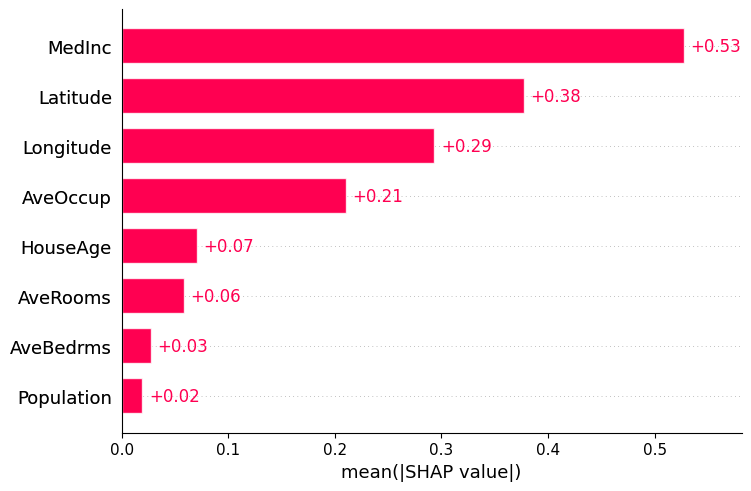

In [24]:
# Plots this view
shap.plots.bar(shap_values)

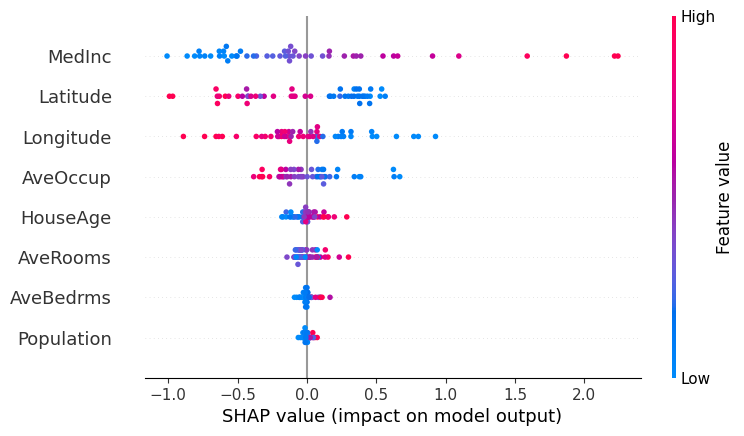

In [25]:
# Plots the beeswarm
shap.plots.beeswarm(shap_values.sample(50))

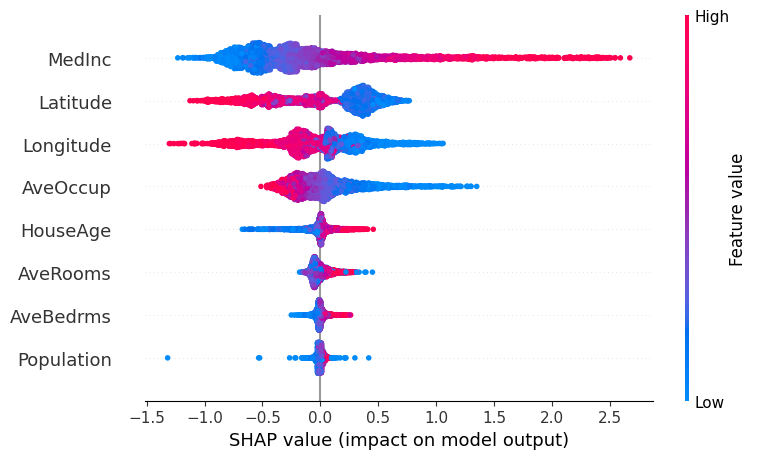

In [26]:
shap.summary_plot(shap_values)

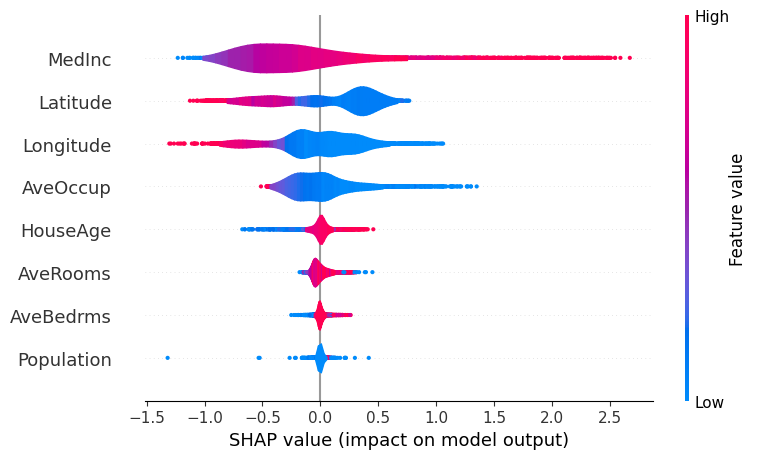

In [27]:
# Violin plot
shap.summary_plot(shap_values, plot_type='violin')

In [28]:
# Prints the SHAP feature importances
print_feature_importances_shap_values(shap_values, X_test.columns)

MedInc -> 0.5274 (softmax = 0.1710)
Latitude -> 0.3775 (softmax = 0.1472)
Longitude -> 0.2933 (softmax = 0.1353)
AveOccup -> 0.2101 (softmax = 0.1245)
HouseAge -> 0.0707 (softmax = 0.1083)
AveRooms -> 0.0582 (softmax = 0.1070)
AveBedrms -> 0.0272 (softmax = 0.1037)
Population -> 0.0193 (softmax = 0.1029)


### SHAP local evaluation
For a single example

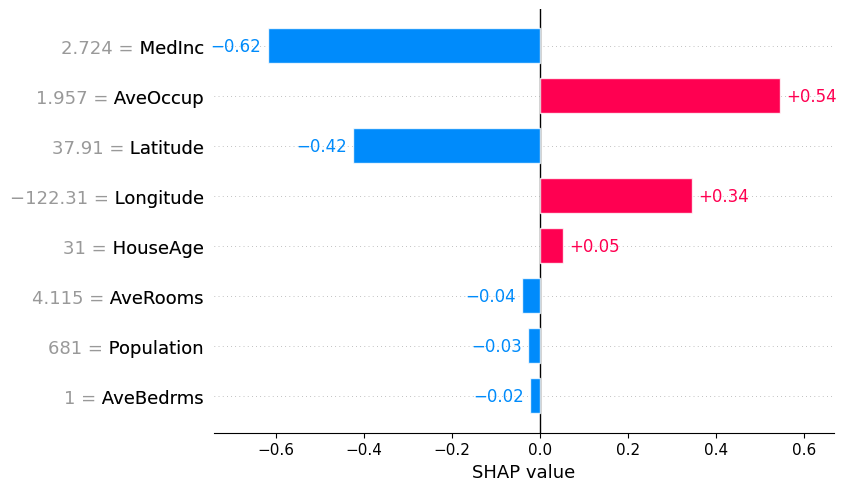

In [29]:
shap.plots.bar(shap_values[0])

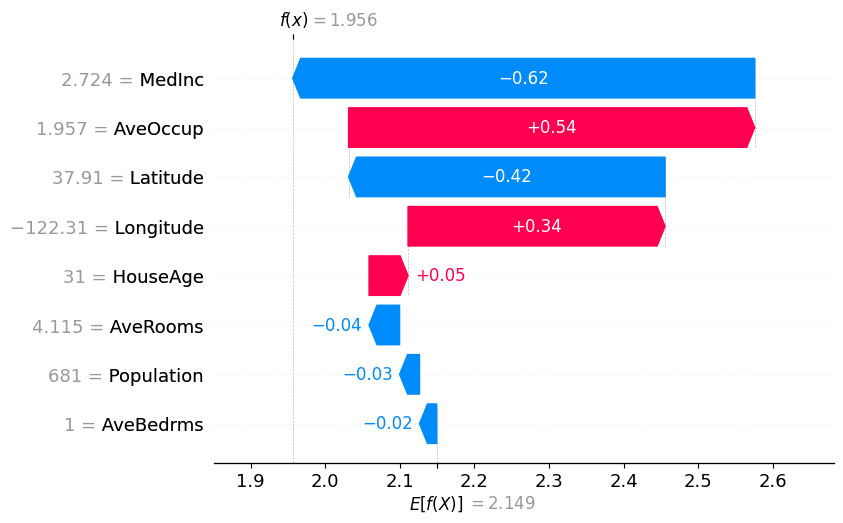

In [30]:
shap.plots.waterfall(shap_values[0], max_display=10)

In [31]:
shap.initjs()
shap.plots.force(shap_values[0])